<a href="https://colab.research.google.com/github/sahil03kundu-code/AIML-LAB/blob/main/AI_LAB5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Install imbalanced-learn (required for SMOTE)
!pip -q install imbalanced-learn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

from imblearn.over_sampling import SMOTE

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
from google.colab import files

uploaded = files.upload()

# Upload the processed Stroke Dataset CSV file.
# If your file has a different name, update the filename below.
df = pd.read_csv("stroke_processed_5k.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)
display(df.head())

Saving stroke_processed_5k.csv to stroke_processed_5k.csv
Dataset loaded successfully!
Dataset Shape: (5110, 11)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,1.051434,0,1,1,2,1,2.706375,1.005086,1,1
1,0,0.786070,0,0,1,3,0,2.121559,-0.098981,2,1
2,1,1.626390,0,1,1,2,0,-0.005028,0.472536,2,1
3,0,0.255342,0,0,1,2,1,1.437358,0.719327,3,1
4,0,1.582163,1,0,1,3,0,1.501184,-0.631531,2,1


In [4]:
print("Dataset Information:")
df.info()

print("\\nMissing Values:")
print(df.isnull().sum())

print("\\nTarget Distribution:")
print(df["stroke"].value_counts())

print("\\nTarget Distribution in Percentage:")
print((df["stroke"].value_counts(normalize=True) * 100).round(2))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   int64  
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   int64  
 5   work_type          5110 non-null   int64  
 6   Residence_type     5110 non-null   int64  
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                5110 non-null   float64
 9   smoking_status     5110 non-null   int64  
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(8)
memory usage: 439.3 KB
\nMissing Values:
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level

In [5]:
# Separate input features and target variable
X = df.drop("stroke", axis=1)
y = df["stroke"]

# Ensure that all feature columns are numeric
if not all(pd.api.types.is_numeric_dtype(dtype) for dtype in X.dtypes):
    raise ValueError("Non-numeric columns found. Encode categorical columns before applying SMOTE.")

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("\\nFeature Columns:")
print(X.columns.tolist())

Features Shape: (5110, 10)
Target Shape: (5110,)
\nFeature Columns:
['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status']


In [6]:
# Split before applying SMOTE so that the test set remains untouched
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\\nOriginal Training Target Distribution:")
print(y_train.value_counts().sort_index())

print("\\nTesting Target Distribution:")
print(y_test.value_counts().sort_index())

Training Data: (4088, 10)
Testing Data: (1022, 10)
\nOriginal Training Target Distribution:
stroke
0    3889
1     199
Name: count, dtype: int64
\nTesting Target Distribution:
stroke
0    972
1     50
Name: count, dtype: int64


In [7]:
# Scale using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


Class distribution before SMOTE:
stroke
0    3889
1     199
Name: count, dtype: int64
\nClass distribution after SMOTE:
stroke
0    3889
1    3889
Name: count, dtype: int64


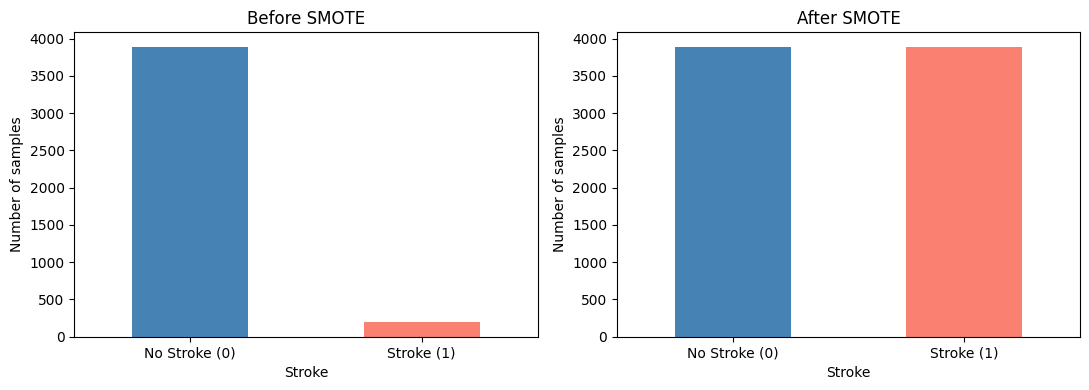

In [8]:
print("Class distribution before SMOTE:")
print(y_train.value_counts().sort_index())

# Select a valid neighbour count if the minority class is very small
minority_count = y_train.value_counts().min()
if minority_count < 2:
    raise ValueError("SMOTE requires at least two samples in the minority class.")

smote_neighbors = min(5, minority_count - 1)

smote = SMOTE(
    sampling_strategy="auto",
    random_state=42,
    k_neighbors=smote_neighbors
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("\\nClass distribution after SMOTE:")
print(pd.Series(y_train_smote).value_counts().sort_index())

# Visualize class distribution before and after SMOTE
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

y_train.value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color=["steelblue", "salmon"]
)
axes[0].set_title("Before SMOTE")
axes[0].set_xlabel("Stroke")
axes[0].set_ylabel("Number of samples")
axes[0].set_xticklabels(["No Stroke (0)", "Stroke (1)"], rotation=0)

pd.Series(y_train_smote).value_counts().sort_index().plot(
    kind="bar", ax=axes[1], color=["steelblue", "salmon"]
)
axes[1].set_title("After SMOTE")
axes[1].set_xlabel("Stroke")
axes[1].set_ylabel("Number of samples")
axes[1].set_xticklabels(["No Stroke (0)", "Stroke (1)"], rotation=0)

plt.tight_layout()
plt.show()

In [9]:
def create_models():
    return {
        "Logistic Regression": LogisticRegression(
            max_iter=2000,
            random_state=42
        ),

        "Decision Tree": DecisionTreeClassifier(
            max_depth=8,
            min_samples_leaf=5,
            random_state=42
        ),

        "Random Forest": RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ),

        "SVM": SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ),

        "KNN": KNeighborsClassifier(
            n_neighbors=7,
            weights="distance"
        ),

        "ANN (MLP)": MLPClassifier(
            hidden_layer_sizes=(64, 32),
            activation="relu",
            solver="adam",
            alpha=0.001,
            max_iter=500,
            early_stopping=True,
            random_state=42
        )
    }

print("Six classification models defined successfully!")

Six classification models defined successfully!


In [10]:
original_models = create_models()

original_results = []
original_predictions = {}
original_probabilities = {}
original_confusion_matrices = {}

for name, model in original_models.items():
    print(f"Training {name} on original imbalanced data...")

    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    original_predictions[name] = y_pred
    original_probabilities[name] = y_prob

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    original_confusion_matrices[name] = cm

    original_results.append({
        "Model": name,
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC-ROC": roc_auc_score(y_test, y_prob)
    })

original_results_df = pd.DataFrame(original_results)

print("\\nOriginal imbalanced dataset results:")
display(original_results_df.style.format({
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1-Score": "{:.4f}",
    "Accuracy": "{:.4f}",
    "AUC-ROC": "{:.4f}"
}))

Training Logistic Regression on original imbalanced data...
Training Decision Tree on original imbalanced data...
Training Random Forest on original imbalanced data...
Training SVM on original imbalanced data...
Training KNN on original imbalanced data...
Training ANN (MLP) on original imbalanced data...
\nOriginal imbalanced dataset results:


,Model,Precision,Recall,F1-Score,Accuracy,AUC-ROC
0,Logistic Regression,0.0000,0.0000,0.0000,0.9511,0.8377
1,Decision Tree,0.1250,0.0200,0.0345,0.9452,0.7647
2,Random Forest,0.0000,0.0000,0.0000,0.9501,0.8268
3,SVM,0.0000,0.0000,0.0000,0.9511,0.6108
4,KNN,0.0000,0.0000,0.0000,0.9462,0.6206
5,ANN (MLP),0.0000,0.0000,0.0000,0.9511,0.5411


In [11]:
smote_models = create_models()

smote_results = []
smote_predictions = {}
smote_probabilities = {}
smote_confusion_matrices = {}

for name, model in smote_models.items():
    print(f"Training {name} on SMOTE-balanced data...")

    model.fit(X_train_smote, y_train_smote)

    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    smote_predictions[name] = y_pred
    smote_probabilities[name] = y_prob

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    smote_confusion_matrices[name] = cm

    smote_results.append({
        "Model": name,
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0),
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC-ROC": roc_auc_score(y_test, y_prob)
    })

smote_results_df = pd.DataFrame(smote_results)

print("\\nSMOTE-balanced dataset results:")
display(smote_results_df.style.format({
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1-Score": "{:.4f}",
    "Accuracy": "{:.4f}",
    "AUC-ROC": "{:.4f}"
}))

Training Logistic Regression on SMOTE-balanced data...
Training Decision Tree on SMOTE-balanced data...
Training Random Forest on SMOTE-balanced data...
Training SVM on SMOTE-balanced data...
Training KNN on SMOTE-balanced data...
Training ANN (MLP) on SMOTE-balanced data...
\nSMOTE-balanced dataset results:


,Model,Precision,Recall,F1-Score,Accuracy,AUC-ROC
0,Logistic Regression,0.1460,0.8000,0.2469,0.7613,0.8381
1,Decision Tree,0.1333,0.4000,0.2000,0.8434,0.7678
2,Random Forest,0.1800,0.1800,0.1800,0.9198,0.7936
3,SVM,0.1179,0.5800,0.1959,0.7671,0.7762
4,KNN,0.0899,0.3400,0.1423,0.7994,0.6553
5,ANN (MLP),0.1176,0.2800,0.1657,0.8620,0.7659


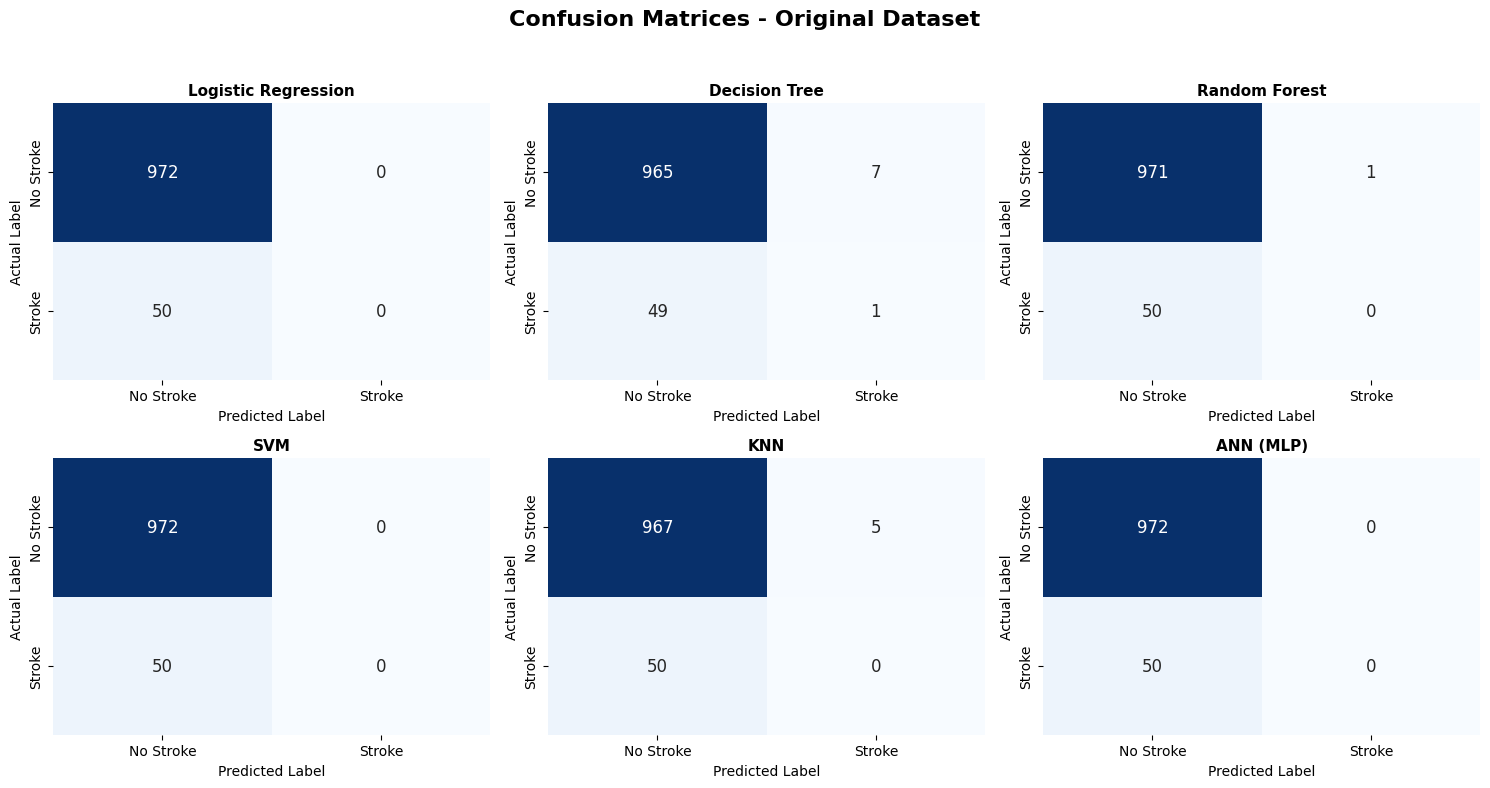

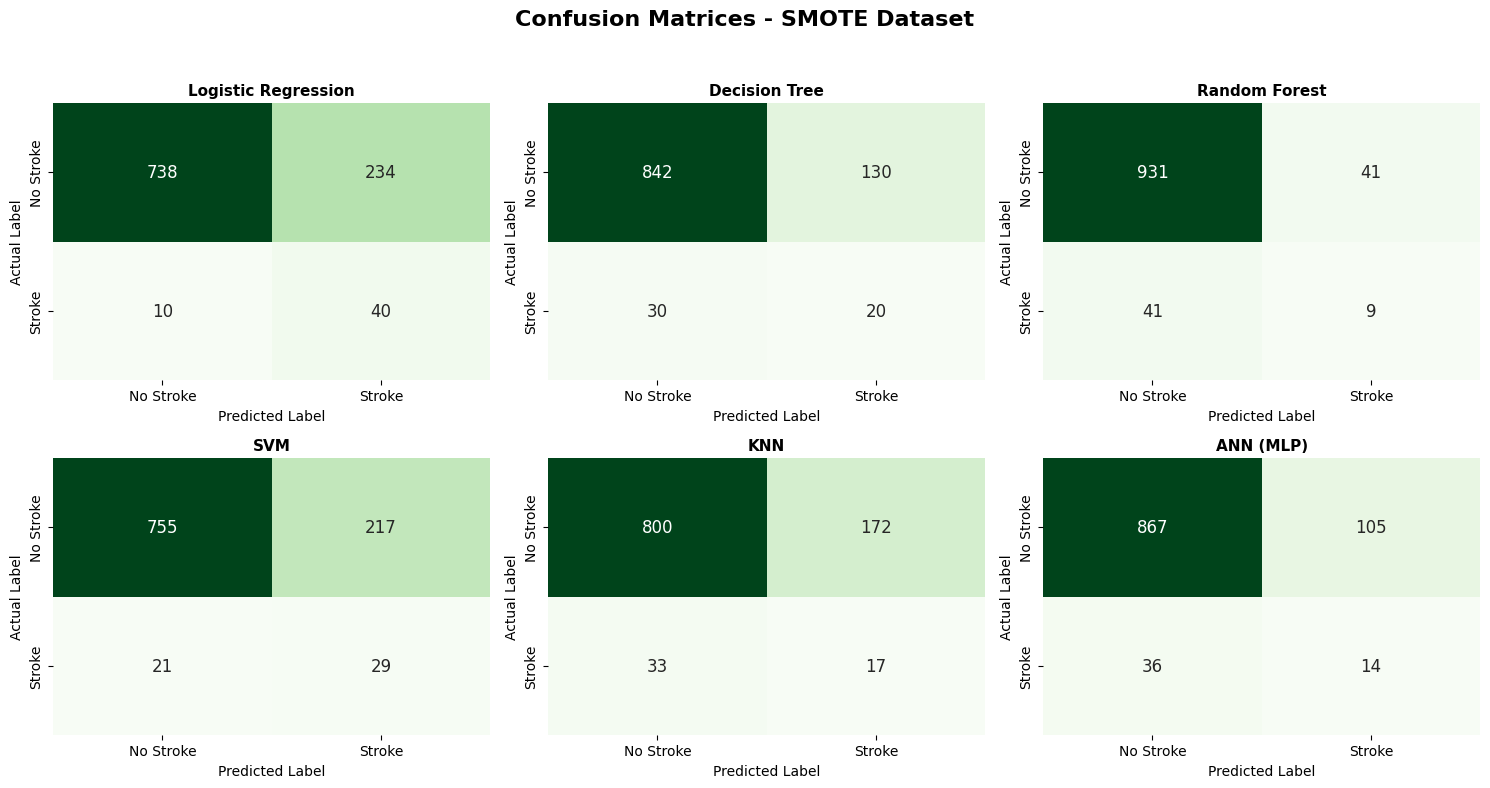

In [12]:

# Display all confusion matrices in a compact 2x3 layout

def plot_confusion_matrices(cm_dict, title, cmap):

    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    axes = axes.flatten()

    for ax, (name, cm) in zip(axes, cm_dict.items()):

        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap=cmap,
            xticklabels=["No Stroke", "Stroke"],
            yticklabels=["No Stroke", "Stroke"],
            ax=ax,
            cbar=False,
            annot_kws={"size": 12}
        )

        ax.set_title(name, fontsize=11, fontweight="bold")
        ax.set_xlabel("Predicted Label")
        ax.set_ylabel("Actual Label")

    fig.suptitle(title, fontsize=16, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()


# Original dataset confusion matrices
plot_confusion_matrices(
    original_confusion_matrices,
    "Confusion Matrices - Original Dataset",
    "Blues"
)

# SMOTE dataset confusion matrices
plot_confusion_matrices(
    smote_confusion_matrices,
    "Confusion Matrices - SMOTE Dataset",
    "Greens"
)


In [13]:
metrics = [
    "Precision",
    "Recall",
    "F1-Score",
    "Accuracy",
    "AUC-ROC"
]

comparison_df = original_results_df.merge(
    smote_results_df,
    on="Model",
    suffixes=("_Original", "_SMOTE")
)

comparison_columns = ["Model"]
for metric in metrics:
    comparison_columns.extend([f"{metric}_Original", f"{metric}_SMOTE"])

comparison_df = comparison_df[comparison_columns]

print("Comparative Performance: Original vs SMOTE")
display(comparison_df.style.format({
    col: "{:.4f}" for col in comparison_df.columns if col != "Model"
}))

Comparative Performance: Original vs SMOTE


,Model,Precision_Original,Precision_SMOTE,Recall_Original,Recall_SMOTE,F1-Score_Original,F1-Score_SMOTE,Accuracy_Original,Accuracy_SMOTE,AUC-ROC_Original,AUC-ROC_SMOTE
0,Logistic Regression,0.0000,0.1460,0.0000,0.8000,0.0000,0.2469,0.9511,0.7613,0.8377,0.8381
1,Decision Tree,0.1250,0.1333,0.0200,0.4000,0.0345,0.2000,0.9452,0.8434,0.7647,0.7678
2,Random Forest,0.0000,0.1800,0.0000,0.1800,0.0000,0.1800,0.9501,0.9198,0.8268,0.7936
3,SVM,0.0000,0.1179,0.0000,0.5800,0.0000,0.1959,0.9511,0.7671,0.6108,0.7762
4,KNN,0.0000,0.0899,0.0000,0.3400,0.0000,0.1423,0.9462,0.7994,0.6206,0.6553
5,ANN (MLP),0.0000,0.1176,0.0000,0.2800,0.0000,0.1657,0.9511,0.8620,0.5411,0.7659


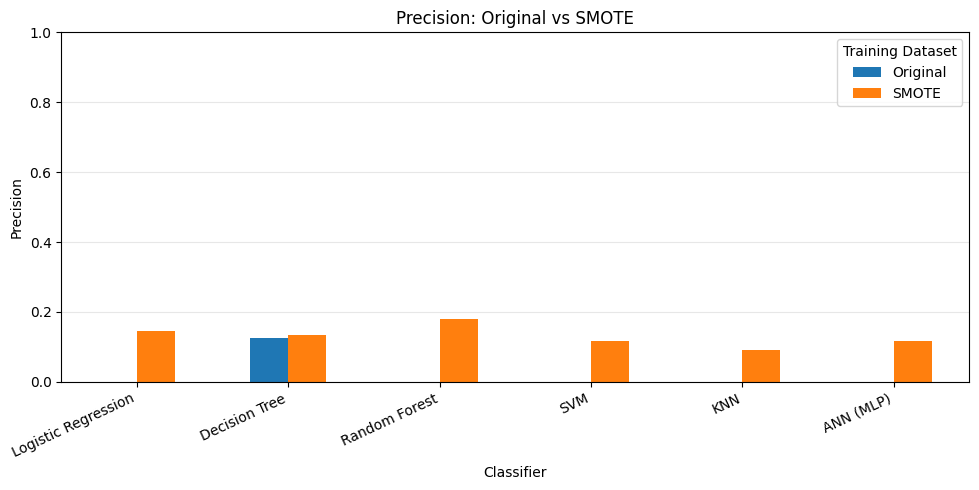

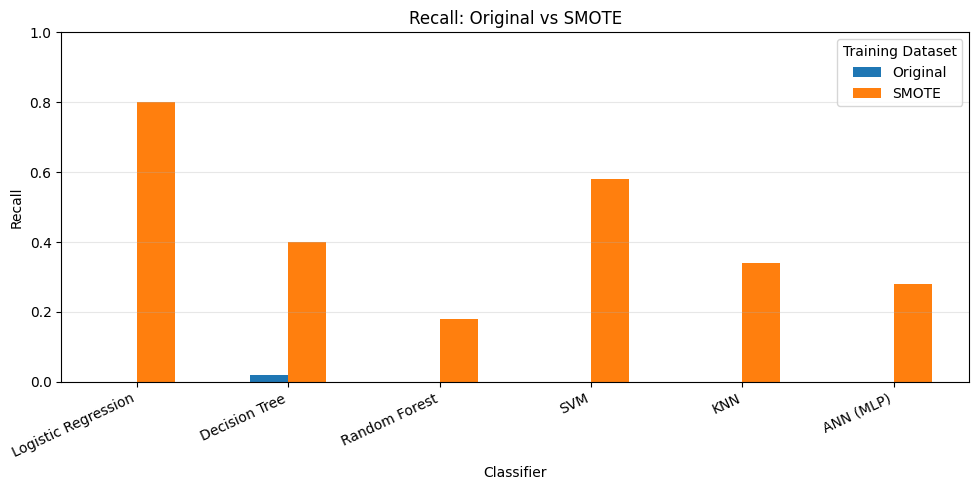

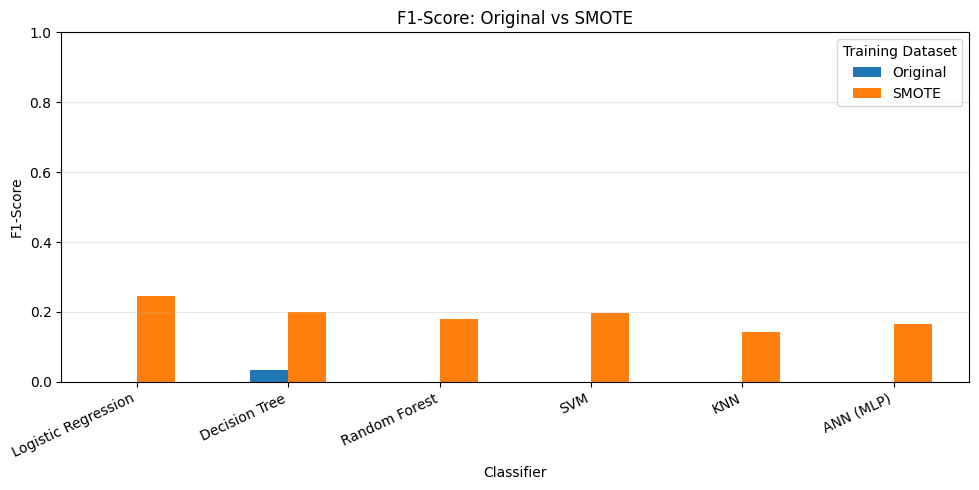

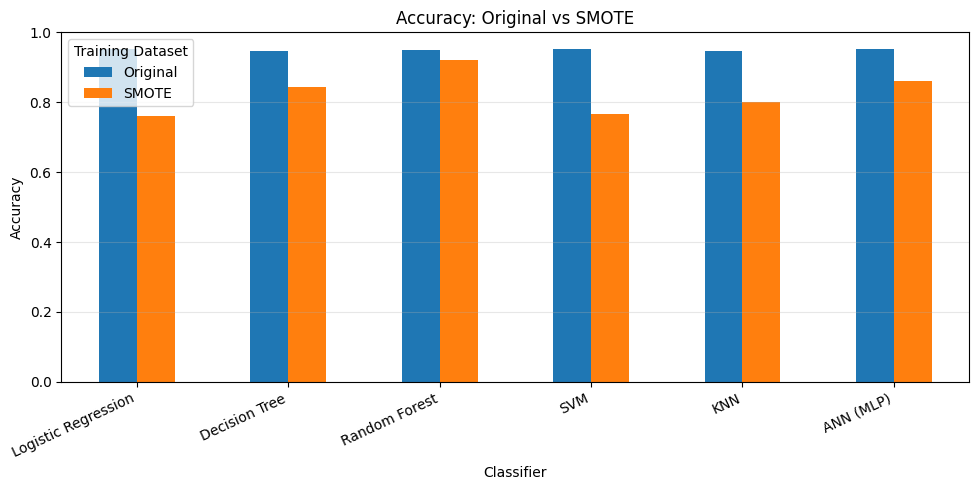

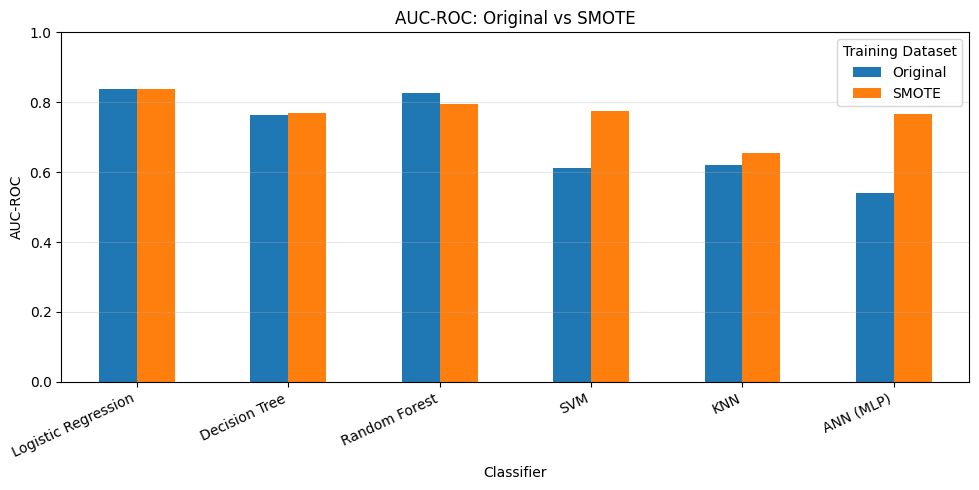

In [14]:
# Plot comparison for each evaluation metric
for metric in metrics:
    plot_df = comparison_df.set_index("Model")[
        [f"{metric}_Original", f"{metric}_SMOTE"]
    ]
    plot_df.columns = ["Original", "SMOTE"]

    plot_df.plot(kind="bar", figsize=(10, 5))
    plt.title(f"{metric}: Original vs SMOTE")
    plt.ylabel(metric)
    plt.xlabel("Classifier")
    plt.ylim(0, 1)
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.legend(title="Training Dataset")
    plt.tight_layout()
    plt.show()

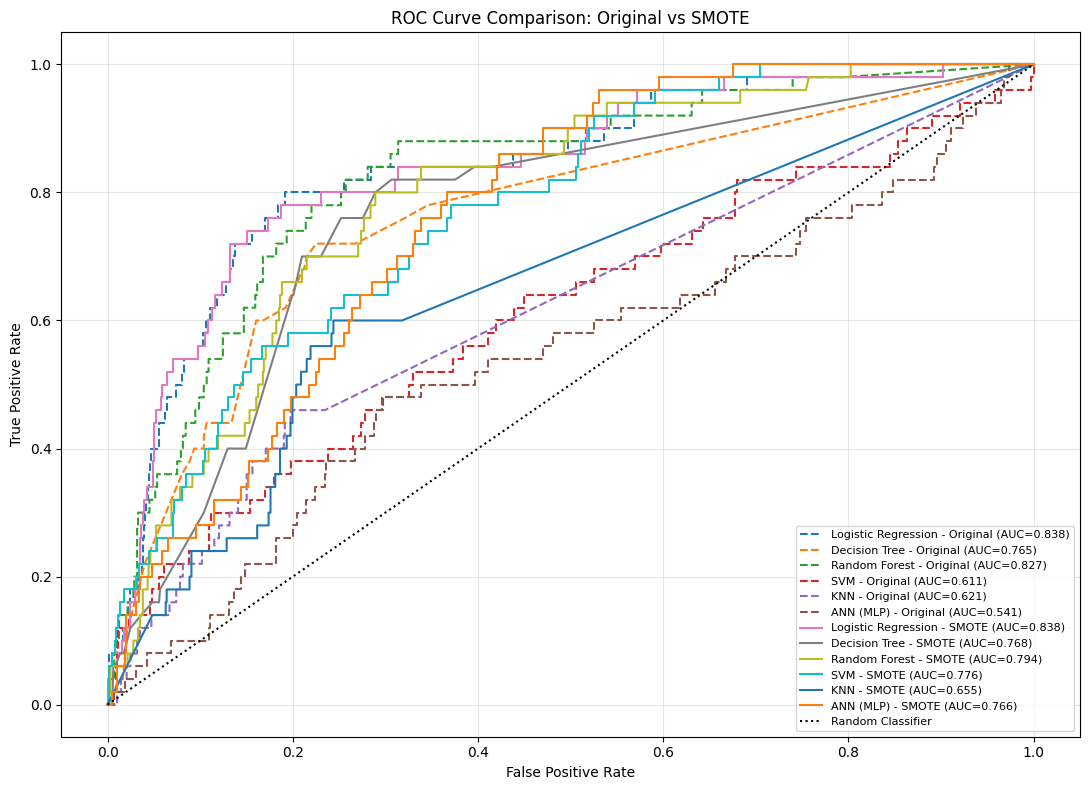

In [ ]:
plt.figure(figsize=(11, 8))

for name, y_prob in original_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_value = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, linestyle="--",
             label=f"{name} - Original (AUC={auc_value:.3f})")

for name, y_prob in smote_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_value = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr,
             label=f"{name} - SMOTE (AUC={auc_value:.3f})")

plt.plot([0, 1], [0, 1], color="black", linestyle=":",
         label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison: Original vs SMOTE")
plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Top Three Models on SMOTE-Balanced Training Data:


,Rank,Model,Precision,Recall,F1-Score,Accuracy,AUC-ROC
0,1,Logistic Regression,0.1460,0.8000,0.2469,0.7613,0.8381
2,2,Random Forest,0.1800,0.1800,0.1800,0.9198,0.7936
3,3,SVM,0.1179,0.5800,0.1959,0.7671,0.7762


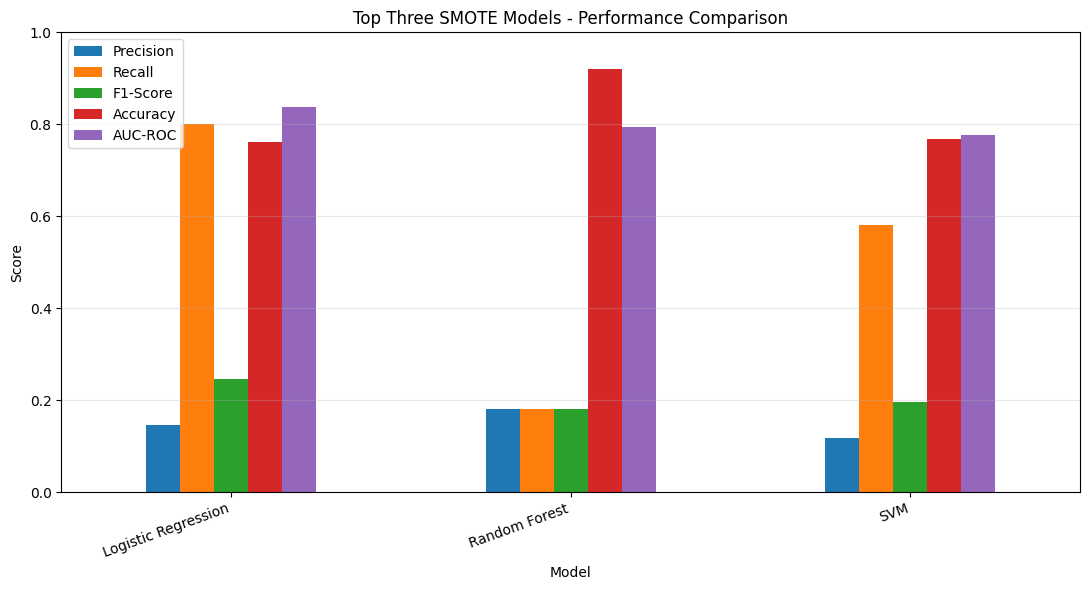

\nConfusion matrices of the top three SMOTE models:
\nLogistic Regression
                  Predicted No Stroke  Predicted Stroke
Actual No Stroke                  738               234
Actual Stroke                      10                40
\nRandom Forest
                  Predicted No Stroke  Predicted Stroke
Actual No Stroke                  931                41
Actual Stroke                      41                 9
\nSVM
                  Predicted No Stroke  Predicted Stroke
Actual No Stroke                  755               217
Actual Stroke                      21                29


In [ ]:
top_three = smote_results_df.sort_values(
    by=["AUC-ROC", "Recall", "F1-Score"],
    ascending=False
).head(3).copy()

top_three.insert(0, "Rank", range(1, len(top_three) + 1))

print("Top Three Models on SMOTE-Balanced Training Data:")
display(top_three.style.format({
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "F1-Score": "{:.4f}",
    "Accuracy": "{:.4f}",
    "AUC-ROC": "{:.4f}"
}))

top_three.drop(columns=["Rank"]).set_index("Model")[metrics].plot(
    kind="bar", figsize=(11, 6)
)
plt.title("Top Three SMOTE Models - Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\\nConfusion matrices of the top three SMOTE models:")
for name in top_three["Model"]:
    print(f"\\n{name}")
    print(pd.DataFrame(
        smote_confusion_matrices[name],
        index=["Actual No Stroke", "Actual Stroke"],
        columns=["Predicted No Stroke", "Predicted Stroke"]
    ))

In [ ]:
print("FINAL COMPARATIVE ANALYSIS")
print("=" * 60)

for metric in metrics:
    best_row = smote_results_df.loc[smote_results_df[metric].idxmax()]
    print(f"Best SMOTE {metric}: {best_row['Model']} ({best_row[metric]:.4f})")

print("\\nTop Three Models (SMOTE):")
print(top_three[["Rank", "Model", "Precision", "Recall",
                 "F1-Score", "Accuracy", "AUC-ROC"]].to_string(index=False))

print("\\nInterpretation:")
print("Compare Recall, F1-Score and AUC-ROC alongside Accuracy.")
print("SMOTE may improve minority-class detection, but it can also increase false positives.")
print("The best model should be selected based on the evaluation objective, not accuracy alone.")

FINAL COMPARATIVE ANALYSIS
Best SMOTE Precision: Random Forest (0.1800)
Best SMOTE Recall: Logistic Regression (0.8000)
Best SMOTE F1-Score: Logistic Regression (0.2469)
Best SMOTE Accuracy: Random Forest (0.9198)
Best SMOTE AUC-ROC: Logistic Regression (0.8381)
\nTop Three Models (SMOTE):
 Rank               Model  Precision  Recall  F1-Score  Accuracy  AUC-ROC
    1 Logistic Regression   0.145985    0.80  0.246914  0.761252 0.838066
    2       Random Forest   0.180000    0.18  0.180000  0.919765 0.793591
    3                 SVM   0.117886    0.58  0.195946  0.767123 0.776235
\nInterpretation:
Compare Recall, F1-Score and AUC-ROC alongside Accuracy.
SMOTE may improve minority-class detection, but it can also increase false positives.
The best model should be selected based on the evaluation objective, not accuracy alone.


In [ ]:
# Save full results and comparison tables
original_results_df.to_csv("stroke_original_imbalanced_results.csv", index=False)
smote_results_df.to_csv("stroke_smote_balanced_results.csv", index=False)
comparison_df.to_csv("stroke_original_vs_smote_comparison.csv", index=False)
top_three.to_csv("stroke_top_three_smote_models.csv", index=False)

print("All result files saved successfully!")

from google.colab import files

files.download("stroke_original_imbalanced_results.csv")
files.download("stroke_smote_balanced_results.csv")
files.download("stroke_original_vs_smote_comparison.csv")
files.download("stroke_top_three_smote_models.csv")

All result files saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>